In [38]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap.umap_ as umap
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from pathlib import Path

RANDOM_STATE = 231026

## Your task
1. Diagnose dataset using PCA - checking presense of batches/techninical variables in the data.

2. Compare UMAP/tsne/pca projection
3. Validate those plots against present labels


4. Train and evaluate a KNN and SVM model - to predict label, and interpret the results

5. Perform clustering analysis using 2 distict methods and compare clustring results with present labels.

6. Try to decode label meaning

In [39]:
data = pd.read_csv("all_sources_isc_vgg_embeddings.csv")


In [40]:
data

,source,label,Value,vgg_0,vgg_1,vgg_2,vgg_3,vgg_4,vgg_5,vgg_6,...,vgg_502,vgg_503,vgg_504,vgg_505,vgg_506,vgg_507,vgg_508,vgg_509,vgg_510,vgg_511
0,mtt,C,94.774444,0.011359,0.241203,0.344854,0.000000,11.211005,0.004637,0.0,...,0.188881,0.0,0.954637,2.482550,0.000000,0.118003,0.000000,0.000000,1.703285,0.000000
1,mtt,C,94.774444,0.025853,0.000000,1.069848,0.000000,11.320415,0.000000,0.0,...,0.000000,0.0,0.168406,6.162180,0.000000,0.107752,0.000000,0.271620,4.474264,0.000000
2,mtt,C,94.774444,0.480963,0.000000,3.107252,0.000000,4.831994,0.064862,0.0,...,0.124030,0.0,0.665731,1.306546,0.030879,0.144269,0.005907,0.232978,1.154307,0.000000
3,mtt,C,94.774444,0.000000,0.000000,0.058814,0.000000,6.624664,0.000000,0.0,...,0.316281,0.0,0.318968,0.330109,0.480029,0.542135,0.000000,0.008872,3.581180,0.289227
4,mtt,C,94.774444,0.000000,0.000000,0.119758,0.000000,8.961069,0.000000,0.0,...,0.099849,0.0,0.034700,1.626213,0.012560,0.605835,0.000000,0.025230,1.533522,0.180085
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23840,study18,S,NaN,0.059749,0.000000,0.000000,0.312913,0.053099,0.000000,0.0,...,0.198128,0.0,0.024524,0.771849,0.000000,0.002295,0.000000,0.000000,0.800087,0.000000
23841,study18,S,NaN,0.000000,0.000000,1.000184,0.000000,0.740112,0.000000,0.0,...,0.434452,0.0,0.000000,0.732429,0.000000,0.662563,0.000000,0.000000,0.678243,0.000000
23842,study18,S,NaN,0.000000,0.000000,0.677755,0.000000,2.872867,0.000000,0.0,...,2.191196,0.0,0.023503,0.882949,0.000000,0.059748,0.000000,0.000000,0.889415,0.000000
23843,study18,S,NaN,0.000000,0.000000,0.020610,0.000000,2.368106,0.035866,0.0,...,0.834328,0.0,0.051658,0.039791,4.803977,0.000000,0.000000,0.000000,1.185690,0.000000


In [41]:
data.describe()

,Value,vgg_0,vgg_1,vgg_2,vgg_3,vgg_4,vgg_5,vgg_6,vgg_7,vgg_8,...,vgg_502,vgg_503,vgg_504,vgg_505,vgg_506,vgg_507,vgg_508,vgg_509,vgg_510,vgg_511
count,982.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,...,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000
mean,88.145686,1.498470,0.304781,1.085484,0.355538,0.439499,0.131011,0.114659,0.667286,0.026225,...,1.339190,0.166183,1.608867,0.542775,2.118624,0.280964,0.391336,0.088719,1.003547,0.173210
std,61.962304,2.484030,0.705270,1.437526,0.591818,0.949694,0.288222,0.292859,1.165890,0.125531,...,1.733397,0.278504,2.038703,0.907855,1.650250,0.588996,0.685252,0.279512,0.648554,0.408416
min,2.454000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.575000,0.000000,0.000000,0.072552,0.000000,0.000000,0.000000,0.000000,0.005921,0.000000,...,0.307238,0.000000,0.171718,0.029046,0.930009,0.000000,0.000000,0.000000,0.557403,0.000000
50%,94.945000,0.377835,0.000000,0.539538,0.098405,0.091179,0.000811,0.000000,0.172500,0.000000,...,0.838379,0.040099,0.808060,0.189393,1.762812,0.066034,0.064119,0.000000,0.863602,0.015121
75%,120.987500,1.899906,0.273758,1.556678,0.449837,0.510618,0.131086,0.089827,0.762958,0.000000,...,1.746428,0.220630,2.259020,0.676995,2.912449,0.317651,0.496297,0.017148,1.279614,0.148648
max,271.664444,26.383339,11.761838,15.077735,8.261716,16.409120,5.181079,5.634606,12.246122,4.030687,...,18.085924,4.166559,16.153600,16.235281,18.388905,8.562617,8.496418,5.308903,8.755614,8.346353


In [42]:
data.isna().sum()

source         0
label          0
Value      22863
vgg_0          0
vgg_1          0
           ...  
vgg_507        0
vgg_508        0
vgg_509        0
vgg_510        0
vgg_511        0
Length: 515, dtype: int64

why so many "value" values are missing? 
lets check the relation with labels and sources

/var/folders/sy/5plrpq6s4lxb_r_q_7kn2kvc0000gn/T/ipykernel_61029/2325205216.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data["has_value"] = data["Value"].notna()


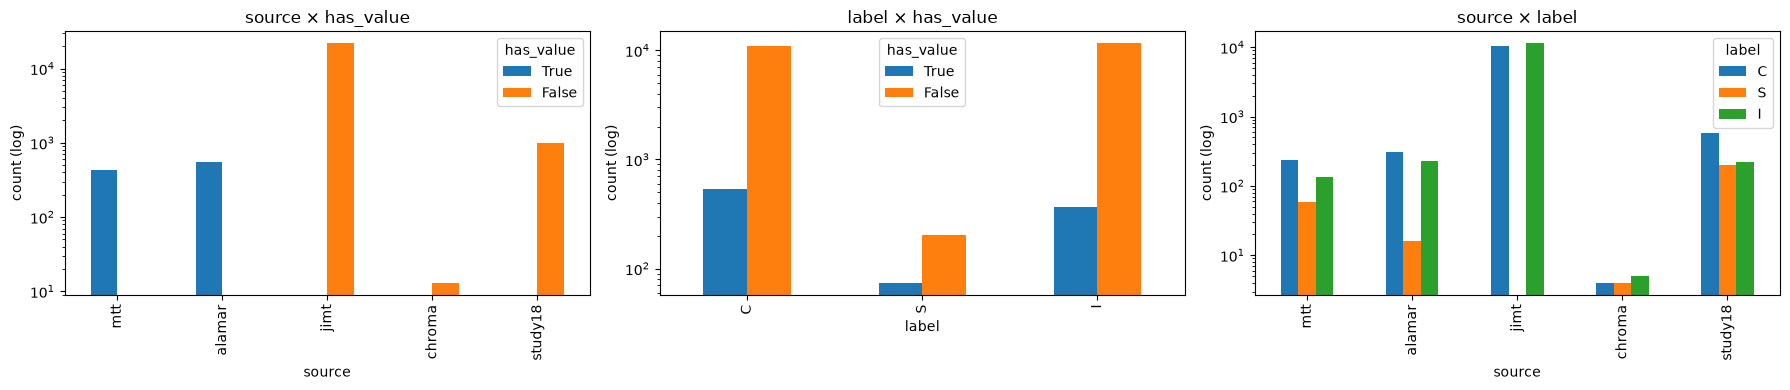

In [43]:
data["has_value"] = data["Value"].notna()
pairs = [("source", "has_value"), ("label", "has_value"), ("source", "label")]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (a, b) in zip(axes, pairs):
    data[[a, b]].value_counts().unstack(fill_value=0).plot.bar(ax=ax, logy=True)
    ax.set(title=f"{a} × {b}", ylabel="count (log)")
plt.tight_layout()

this missingness might be explained by particular datasources, it doesnt have a relation to the label
one more interesting thing is missingness of class S from jimt source, that creates the label imbalance

In [44]:
data["label"].value_counts()

label
I    11978
C    11591
S      276
Name: count, dtype: int64

In [45]:
data["source"].value_counts()

source
jimt       21848
study18     1002
alamar       553
mtt          429
chroma        13
Name: count, dtype: int64

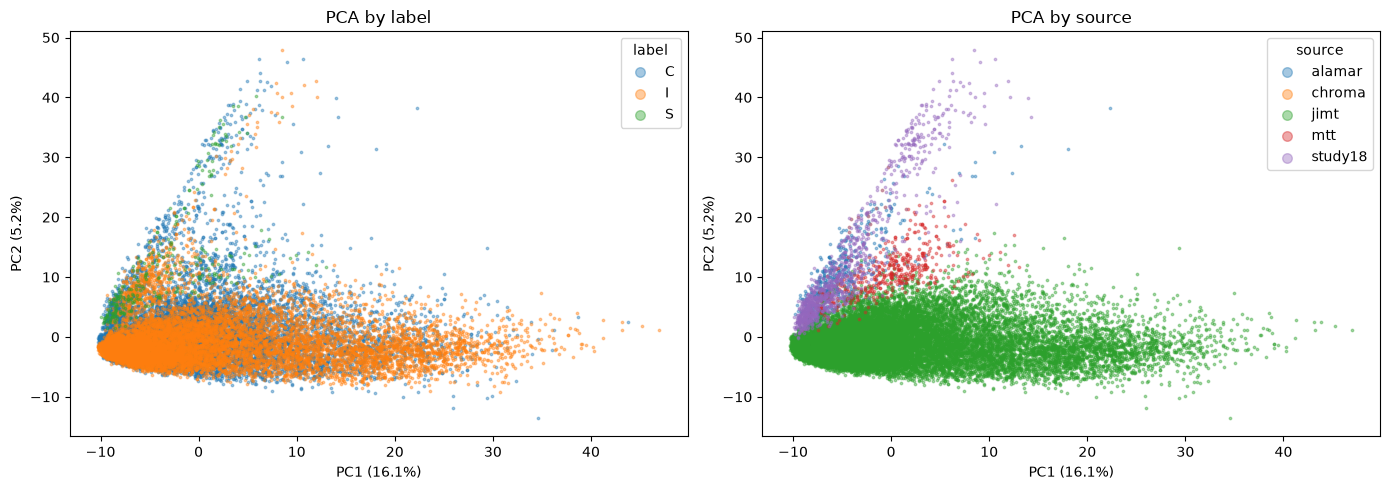

In [46]:
vgg_cols = [c for c in data.columns if c.startswith("vgg_")]
X_scaled = StandardScaler().fit_transform(data[vgg_cols].to_numpy(np.float32))
pca = PCA(n_components=275, svd_solver="randomized", random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["label", "source"]):
    for v in sorted(data[col].unique()):
        m = (data[col] == v).to_numpy()
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=3, alpha=0.4, label=v)
    ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
           ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})", title=f"PCA by {col}")
    ax.legend(title=col, markerscale=4)
plt.tight_layout()

interesting 🤔

class I overlaps with jimt kinda and class S with study18

but two PCAs capture small amount of variation, that might indicate non-linear relation in the data
all of them(sources and labels) seem similar in the beggining and it moves to different directions, my guess right now would be different cell lines, in which most of cells are similar but with some progression they move(disease, aging, etc), and sources are basically datasources

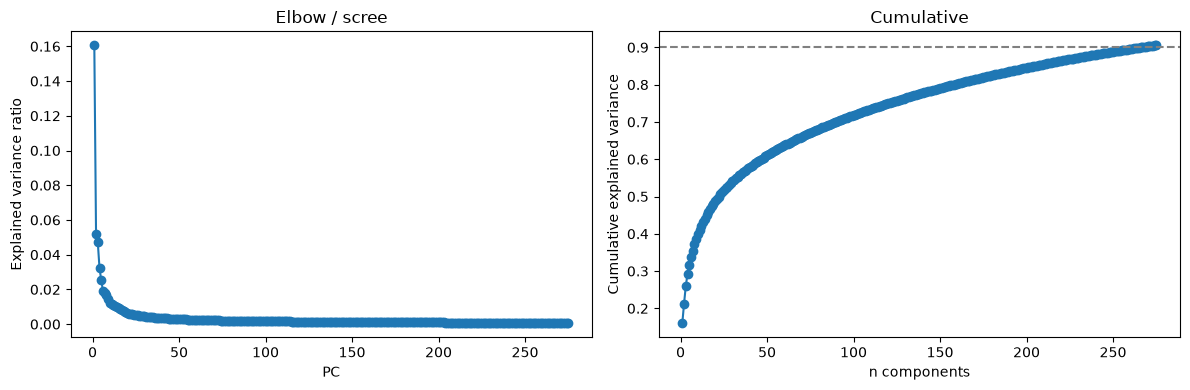

In [47]:
evr = pca.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, len(evr) + 1), evr, marker="o")
axes[0].set(xlabel="PC", ylabel="Explained variance ratio", title="Elbow / scree")
axes[1].plot(np.arange(1, len(evr) + 1), np.cumsum(evr), marker="o")
axes[1].axhline(0.9, color="grey", linestyle="--")
axes[1].set(xlabel="n components", ylabel="Cumulative explained variance", title="Cumulative")
plt.tight_layout()

as was guessed we dont have a big increase in explained variance after 10's PC, that is a sign of non linear relation in the data

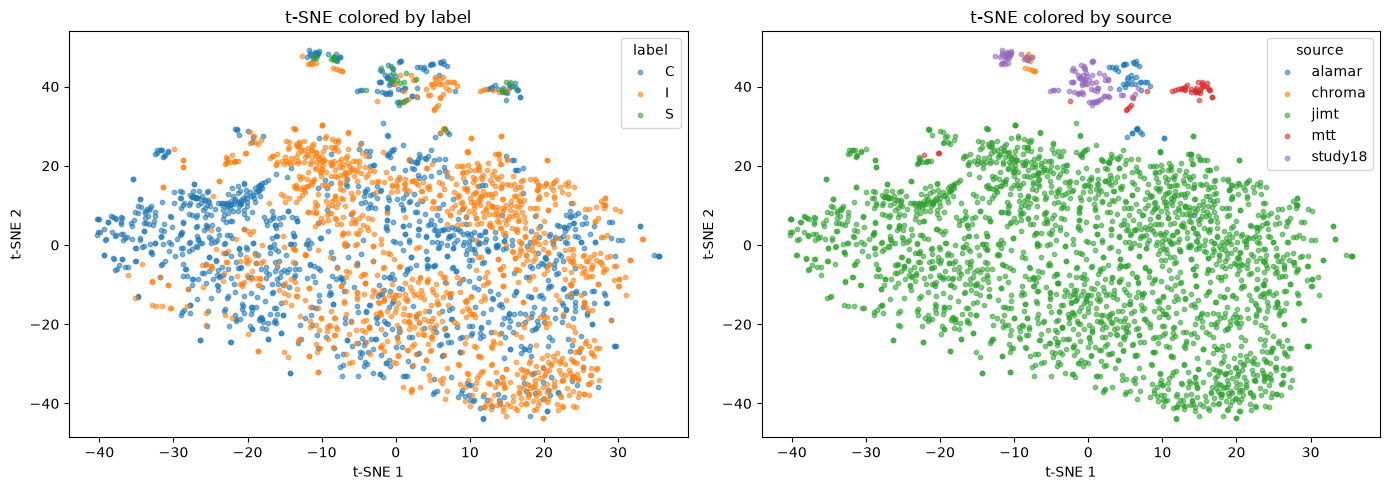

In [48]:
rng = np.random.default_rng(RANDOM_STATE)
chroma_idx = np.where(data["source"] == "chroma")[0]
other_idx = rng.choice(np.where(data["source"] != "chroma")[0], size=2500, replace=False)
idx = np.concatenate([chroma_idx, other_idx])
X_nonlinear = X_pca[idx]
sub = data.iloc[idx].reset_index(drop=True)

tsne = TSNE(n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    max_iter=750,
    random_state=RANDOM_STATE)

X_tsne = tsne.fit_transform(X_nonlinear)
X_tsne

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["label", "source"]):
    for v in sorted(sub[col].unique()):
        mask = (sub[col] == v).to_numpy()
        ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1], s=10, alpha=0.55, label=v)
    ax.set(xlabel="t-SNE 1", ylabel="t-SNE 2", title=f"t-SNE colored by {col}")
    ax.legend(title=col)
plt.tight_layout()

here we can see distinct gouping in the source(jimt) vs others(that are also grouped in their own way, not as obvious as jimt)
and by label we see kinda the division that we saw in the EDA with the label distribution in the data

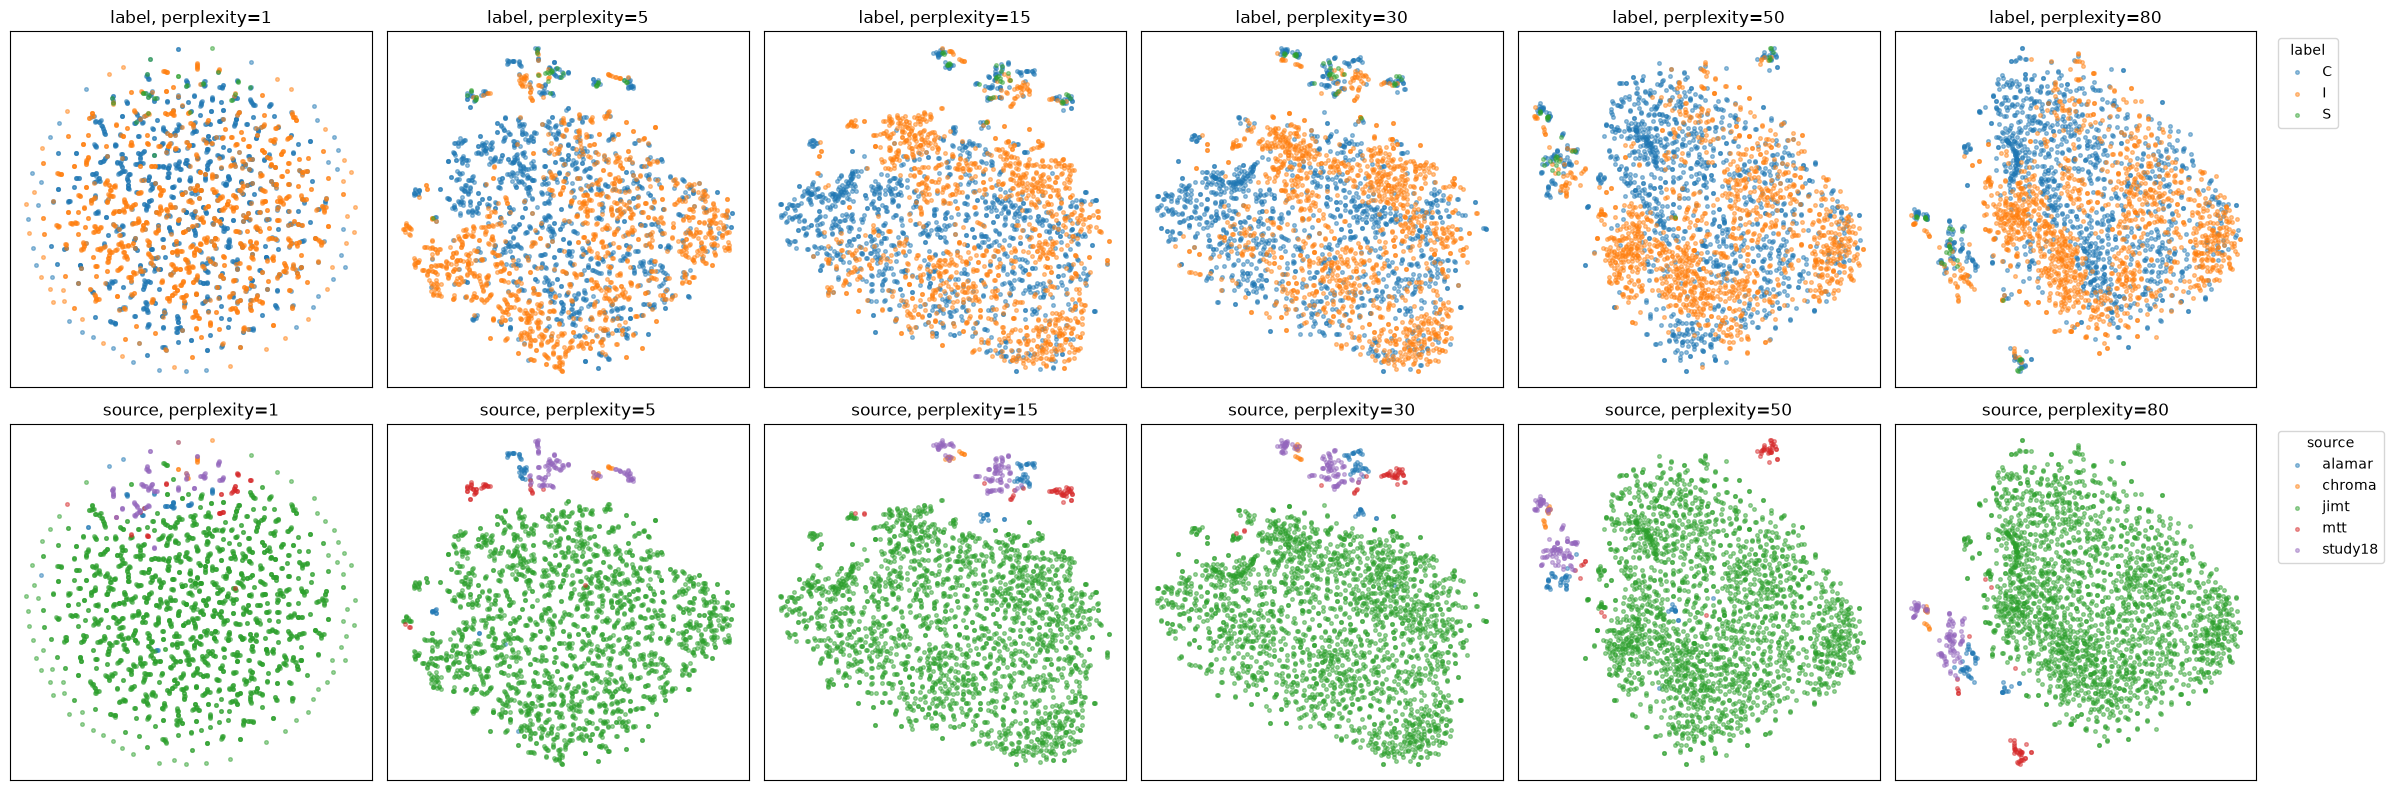

In [49]:
perplexities = [1, 5, 15, 30, 50, 80]
fig, axes = plt.subplots(2, len(perplexities), figsize=(24, 8))
for j, perplexity in enumerate(perplexities):
    embedding = TSNE(n_components=2, perplexity=perplexity, init="pca",
                     learning_rate="auto", max_iter=750,
                     random_state=RANDOM_STATE).fit_transform(X_nonlinear)
    for i, col in enumerate(["label", "source"]):
        ax = axes[i, j]
        for v in sorted(sub[col].unique()):
            mask = (sub[col] == v).to_numpy()
            ax.scatter(embedding[mask, 0], embedding[mask, 1], s=7, alpha=0.45, label=v)
        ax.set_title(f"{col}, perplexity={perplexity}")
        ax.set_xticks([])
        ax.set_yticks([])
axes[0, -1].legend(title="label", bbox_to_anchor=(1.04, 1), loc="upper left")
axes[1, -1].legend(title="source", bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()

i like 15-50 the most   
the grouping is mostly dataset/datasource based, it isnt grouping by label, labels are caried as part of source  
it reflects the local structure, local relation to the neightboring points, distance/size doesnt reflect biology

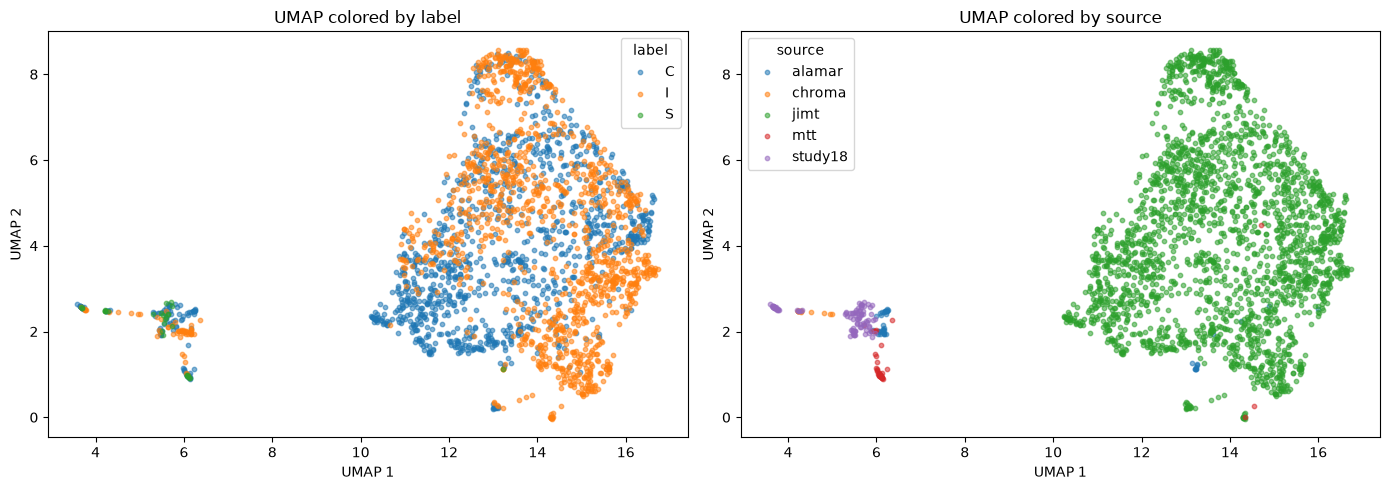

In [50]:
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    random_state=RANDOM_STATE,
    n_jobs=1)
X_umap = reducer.fit_transform(X_nonlinear)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["label", "source"]):
    for v in sorted(sub[col].unique()):
        mask = (sub[col] == v).to_numpy()
        ax.scatter(X_umap[mask, 0], X_umap[mask, 1], s=10, alpha=0.55, label=v)
    ax.set(xlabel="UMAP 1", ylabel="UMAP 2", title=f"UMAP colored by {col}")
    ax.legend(title=col)
plt.tight_layout()

/Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/.venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/.venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/.venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/.venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


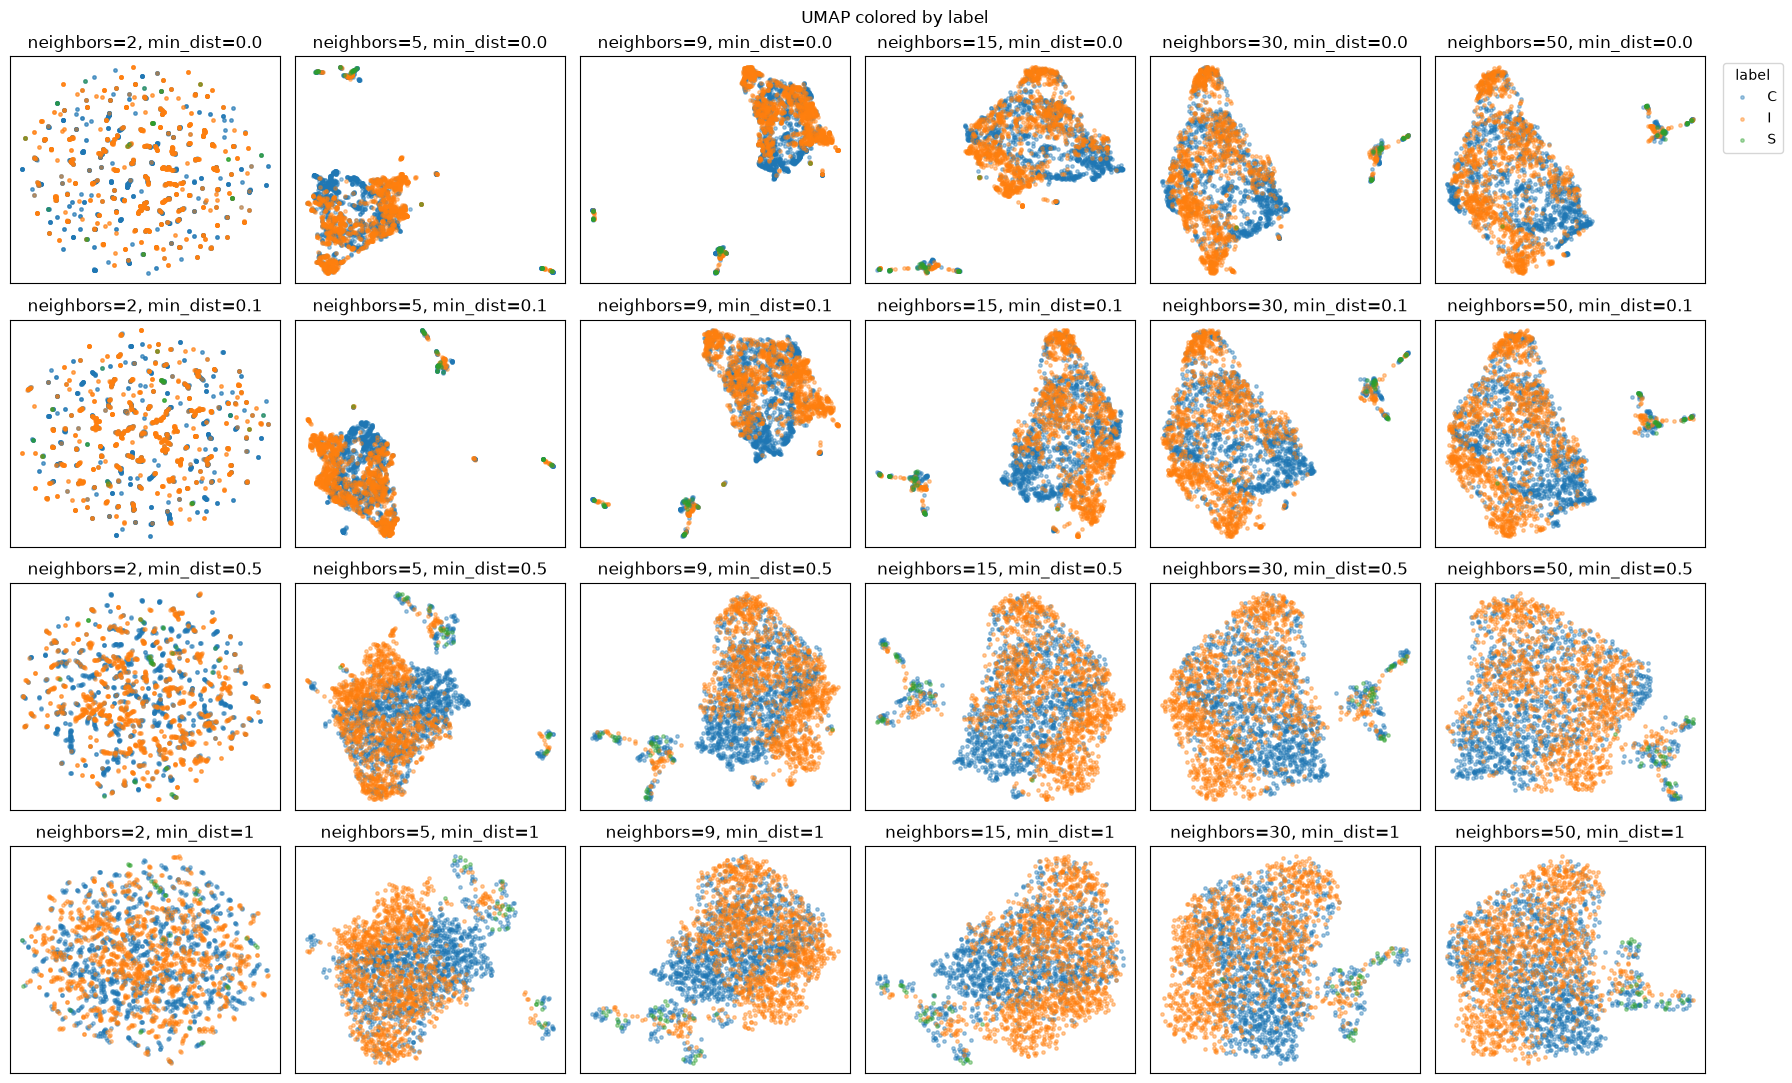

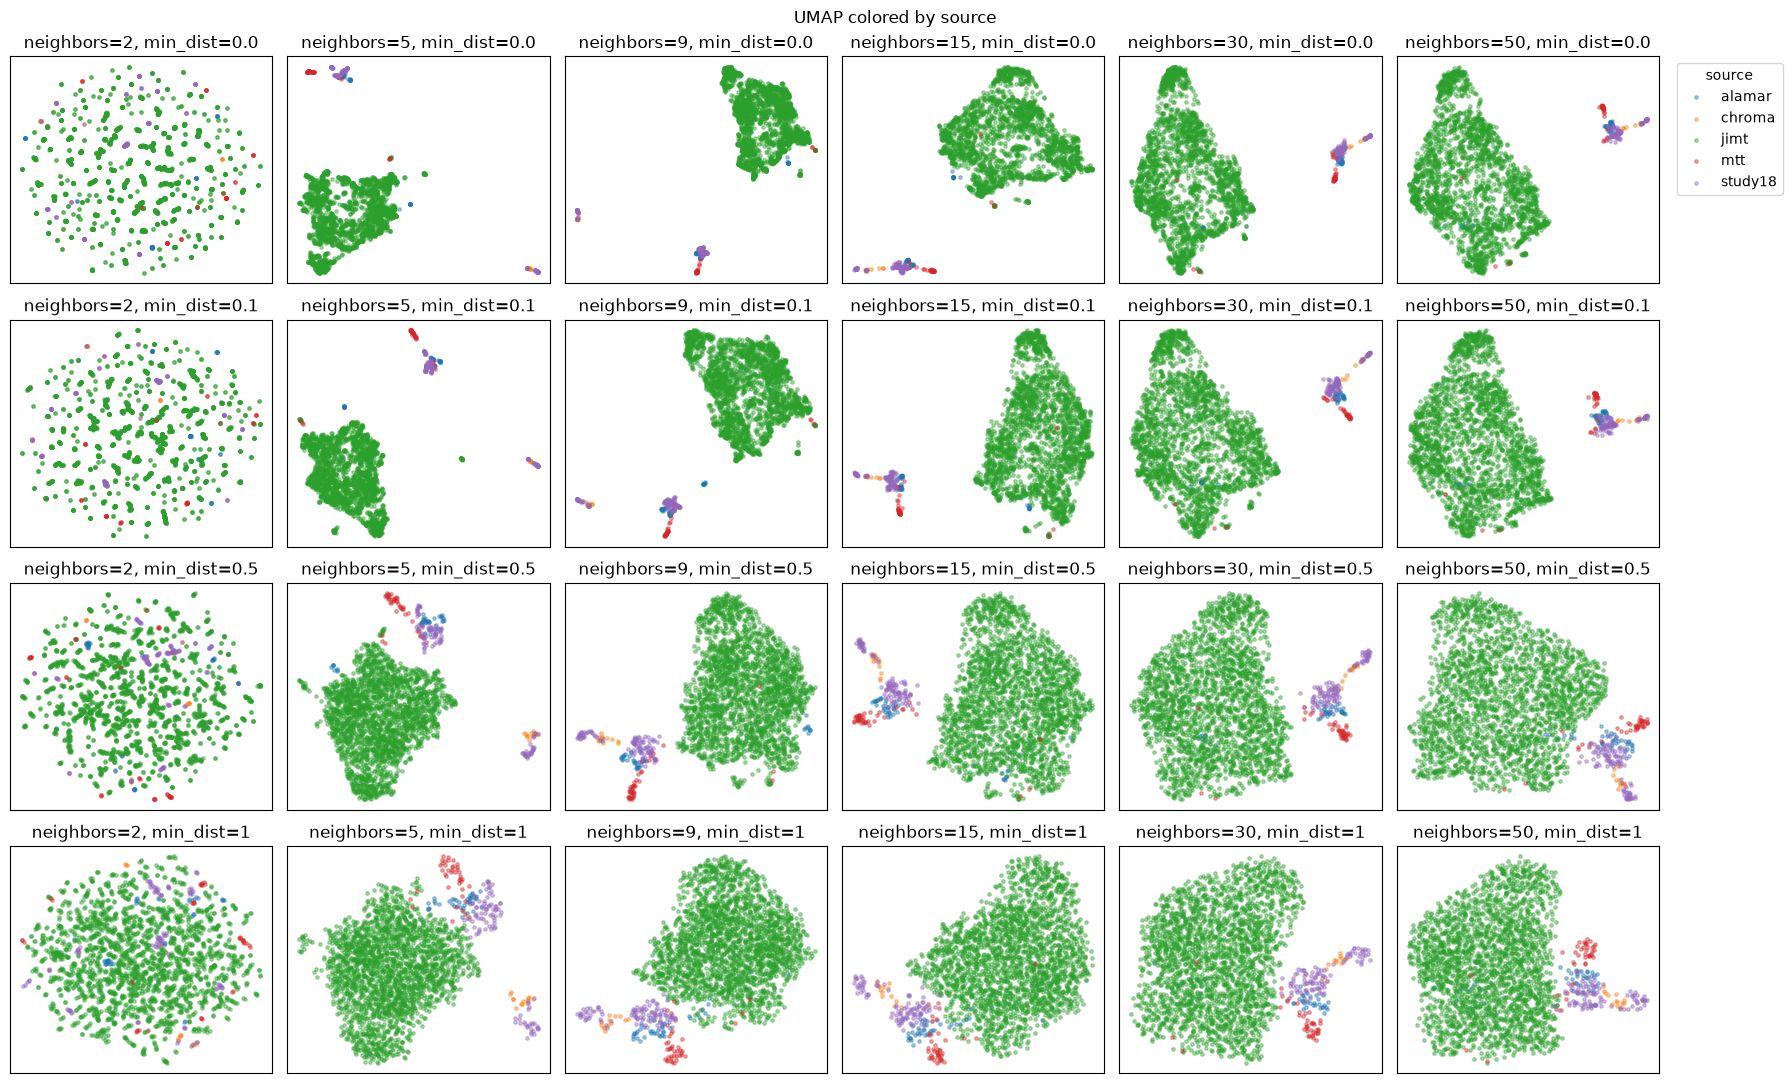

In [51]:
n_neighbors_values = [2, 5, 9, 15, 30, 50]
min_dist_values = [0.0, 0.1, 0.5, 1]

umap_embeddings = {}
for min_dist in min_dist_values:
    for n_neighbors in n_neighbors_values:
        umap_embeddings[(min_dist, n_neighbors)] = umap.UMAP(
            n_neighbors=n_neighbors, min_dist=min_dist,
            random_state=RANDOM_STATE, n_jobs=1).fit_transform(X_nonlinear)

for col in ["label", "source"]:
    fig, axes = plt.subplots(len(min_dist_values), len(n_neighbors_values), figsize=(18, 11))
    for row, min_dist in enumerate(min_dist_values):
        for c, n_neighbors in enumerate(n_neighbors_values):
            embedding = umap_embeddings[(min_dist, n_neighbors)]
            ax = axes[row, c]
            for v in sorted(sub[col].unique()):
                mask = (sub[col] == v).to_numpy()
                ax.scatter(embedding[mask, 0], embedding[mask, 1], s=6, alpha=0.4, label=v)
            ax.set_title(f"neighbors={n_neighbors}, min_dist={min_dist}")
            ax.set_xticks([])
            ax.set_yticks([])
    axes[0, -1].legend(title=col, bbox_to_anchor=(1.04, 1), loc="upper left")
    fig.suptitle(f"UMAP colored by {col}")
    plt.tight_layout()
    plt.show()

kinda similar result to the t-sne, groups are the most seen at dist 0-0.1 and arount 9-30 neightbors
in terms of labels - batch effect of the dataset overpowers the label grouping in the C I labels, S is kinda the outlier there as its not present in the jimt source

In [52]:
strata = data["source"] + "_" + data["label"]

train_valid_df, test_df = train_test_split(data, test_size=0.20, stratify=strata, random_state=RANDOM_STATE)
train_df, valid_df = train_test_split(train_valid_df, test_size=0.25, stratify=strata[train_valid_df.index], random_state=RANDOM_STATE)

X_train, y_train = train_df[vgg_cols], train_df["label"]
X_valid, y_valid = valid_df[vgg_cols], valid_df["label"]
X_test, y_test = test_df[vgg_cols], test_df["label"]
X_train_valid, y_train_valid = train_valid_df[vgg_cols], train_valid_df["label"]

In [53]:
def classifier_metrics(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    return {
        "accuracy": accuracy_score(y_eval, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_eval, predictions),
        "macro_f1": f1_score(y_eval, predictions, average="macro")}

knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
raw_knn_metrics = classifier_metrics(knn_raw, X_valid, y_valid)
display(pd.Series(raw_knn_metrics, name="raw KNN").to_frame())


,raw KNN
accuracy,0.907947
balanced_accuracy,0.708642
macro_f1,0.738306


In [54]:
knn = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))])
knn.fit(X_train, y_train)
scaled_knn_metrics = classifier_metrics(knn, X_valid, y_valid)
display(pd.DataFrame([raw_knn_metrics, scaled_knn_metrics], index=["raw KNN", "scaled KNN"]))


,accuracy,balanced_accuracy,macro_f1
raw KNN,0.907947,0.708642,0.738306
scaled KNN,0.889495,0.690019,0.713702


in our case scaled performed worse, in comparison to the breast cancer dataset, probably normalizing noise to the levels of the real features

,k,accuracy,balanced_accuracy,macro_f1
0,1,0.915915,0.774261,0.759064
1,3,0.902286,0.716815,0.735168
2,5,0.889495,0.690019,0.713702
3,7,0.881527,0.690665,0.720442
4,11,0.867897,0.651296,0.673407
5,21,0.856154,0.631318,0.662894


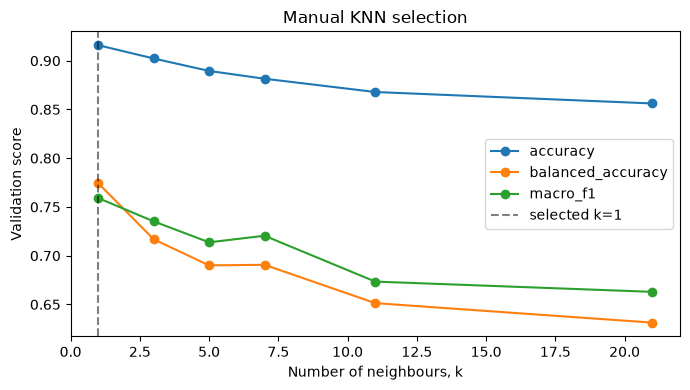

In [55]:
k_values = [1, 3, 5, 7, 11, 21]

knn_results = []
for k in k_values:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k))])
    candidate.fit(X_train, y_train)
    metrics = classifier_metrics(candidate, X_valid, y_valid)
    knn_results.append({"k": k, **metrics})

knn_results = pd.DataFrame(knn_results)
display(knn_results)
best_k = int(knn_results.loc[knn_results["macro_f1"].idxmax(), "k"])

plt.figure(figsize=(7, 4))
for metric in ["accuracy", "balanced_accuracy", "macro_f1"]:
    plt.plot(knn_results["k"], knn_results[metric], marker="o", label=metric)
plt.axvline(best_k, color="black", linestyle="--", alpha=0.5, label=f"selected k={best_k}")
plt.xlabel("Number of neighbours, k")
plt.ylabel("Validation score")
plt.title("Manual KNN selection")
plt.legend()
plt.tight_layout()
plt.show()


due to the class imbalance k-1 wins, with more neighbors S has mostly I/C neighbours

In [56]:
svm_linear = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="linear", C=0.01)),
])
svm_linear.fit(X_train, y_train)
linear_svm_metrics = classifier_metrics(svm_linear, X_valid, y_valid)
display(pd.Series(linear_svm_metrics, name="linear SVM").to_frame())


,linear SVM
accuracy,0.849025
balanced_accuracy,0.705086
macro_f1,0.718362


In [57]:
C_values = [0.01, 0.1, 1]

linear_results = []
for C in C_values:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="linear", C=C)),
    ])
    candidate.fit(X_train, y_train)
    metrics = classifier_metrics(candidate, X_valid, y_valid)
    linear_results.append({"C": C, **metrics})

linear_results = pd.DataFrame(linear_results)
display(linear_results)

,C,accuracy,balanced_accuracy,macro_f1
0,0.01,0.849025,0.705086,0.718362
1,0.10,0.846509,0.727538,0.728989
2,1.00,0.842734,0.700862,0.695161


changing C didnt improve the model

In [58]:
svm_rbf = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="rbf", C=1, gamma=0.01)),
])
svm_rbf.fit(X_train, y_train)
rbf_svm_metrics = classifier_metrics(svm_rbf, X_valid, y_valid)
display(pd.Series(rbf_svm_metrics, name="RBF SVM").to_frame())


,RBF SVM
accuracy,0.863074
balanced_accuracy,0.631049
macro_f1,0.658842


In [59]:
svm_rbf = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="rbf", C=1, gamma=0.1)),
])
svm_rbf.fit(X_train, y_train)
rbf_svm_metrics = classifier_metrics(svm_rbf, X_valid, y_valid)
display(pd.Series(rbf_svm_metrics, name="RBF SVM").to_frame())


,RBF SVM
accuracy,0.608304
balanced_accuracy,0.426300
macro_f1,0.392570


In [60]:
poly_rbf = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="poly", C=10, degree=3)),
])
poly_rbf.fit(X_train, y_train)
poly_svm_metrics = classifier_metrics(poly_rbf, X_valid, y_valid)
display(pd.Series(poly_svm_metrics, name="Poly SVM").to_frame())

,Poly SVM
accuracy,0.898511
balanced_accuracy,0.744599
macro_f1,0.756897


In [61]:
poly_rbf = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="poly", C=10, degree=3, class_weight="balanced")),
])
poly_rbf.fit(X_train, y_train)
poly_svm_metrics = classifier_metrics(poly_rbf, X_valid, y_valid)
display(pd.Series(poly_svm_metrics, name="Poly SVM").to_frame())

,Poly SVM
accuracy,0.891801
balanced_accuracy,0.764190
macro_f1,0.751910


balanced didnt do much, balanced metrix is better, others are worse

In [62]:
poly_rbf = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="poly", C=1, degree=3)),
])
poly_rbf.fit(X_train, y_train)
poly_svm_metrics = classifier_metrics(poly_rbf, X_valid, y_valid)
display(pd.Series(poly_svm_metrics, name="Poly SVM").to_frame())

,Poly SVM
accuracy,0.870623
balanced_accuracy,0.695480
macro_f1,0.721043


In [63]:
poly_rbf = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="poly", C=20, degree=3)),
])
poly_rbf.fit(X_train, y_train)
poly_svm_metrics = classifier_metrics(poly_rbf, X_valid, y_valid)
display(pd.Series(poly_svm_metrics, name="Poly SVM").to_frame())

,Poly SVM
accuracy,0.897463
balanced_accuracy,0.749924
macro_f1,0.752554


In [64]:
poly_rbf = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(kernel="poly", C=10, degree=5)),
])
poly_rbf.fit(X_train, y_train)
poly_svm_metrics = classifier_metrics(poly_rbf, X_valid, y_valid)
display(pd.Series(poly_svm_metrics, name="Poly SVM").to_frame())

,Poly SVM
accuracy,0.777941
balanced_accuracy,0.625650
macro_f1,0.638616


I coulnd find the better args for the SVM. In group winner is poly3 C=10, but knn is still the best

i think the reason is that 'jimt' source that has C I classes randomly distributed in the cloud of values(t-sne/umap representation)

In [65]:
classes = sorted(y_train.unique())
y_train_numeric = y_train.map({c: i for i, c in enumerate(classes)}).to_numpy()

X_train_numeric = X_train.to_numpy(dtype=float)
visual_scaler = StandardScaler()
X_train_scaled_for_visualization = visual_scaler.fit_transform(X_train_numeric)

visual_pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca2 = visual_pca.fit_transform(X_train_scaled_for_visualization)
visual_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", max_iter=750, random_state=RANDOM_STATE)
X_train_tsne2 = visual_tsne.fit_transform(X_train_scaled_for_visualization)

def plot_svm_boundary(ax, X_2d, y_2d, kernel, title):
    parameters = {"kernel": kernel, "C": 1, "gamma": "scale", "class_weight": "balanced"}
    if kernel == "poly":
        parameters.update({"degree": 3, "coef0": 1})
    model = SVC(**parameters)
    model.fit(X_2d, y_2d)
    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    regions = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, regions, alpha=0.18, cmap="tab10", levels=np.arange(len(classes) + 1) - 0.5, vmin=0, vmax=9)
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, cmap="tab10", vmin=0, vmax=9, s=8, edgecolor="white", linewidth=0.25)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

even thos balanced class weight slightly worsen the results - without "balanced" class S is not present at all there

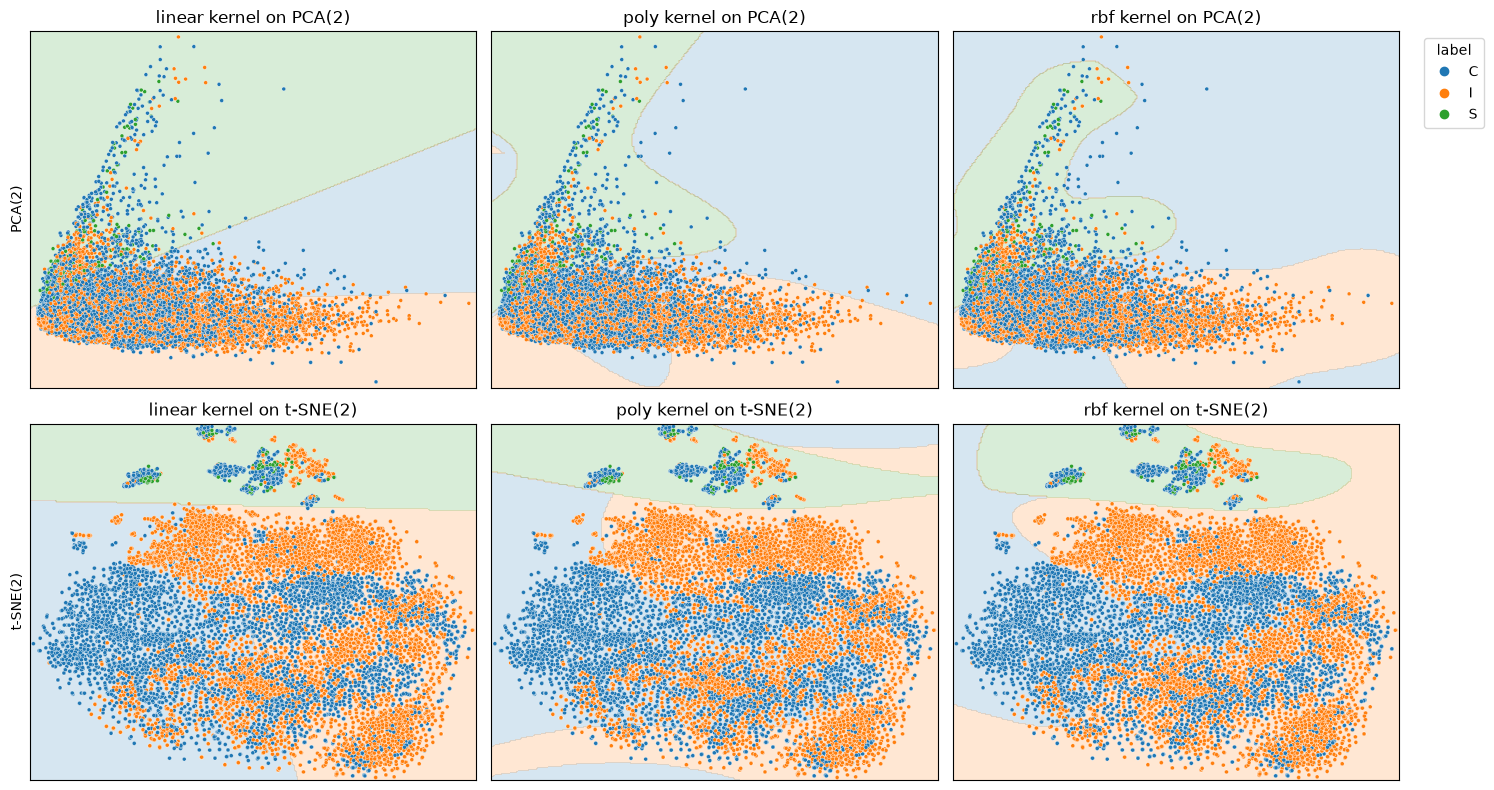

In [66]:
kernels = ["linear", "poly", "rbf"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, kernel in enumerate(kernels):
    plot_svm_boundary(axes[0, column], X_train_pca2, y_train_numeric, kernel, f"{kernel} kernel on PCA(2)")
    plot_svm_boundary(axes[1, column], X_train_tsne2, y_train_numeric, kernel, f"{kernel} kernel on t-SNE(2)")
axes[0, 0].set_ylabel("PCA(2)")
axes[1, 0].set_ylabel("t-SNE(2)")

handles = [plt.Line2D([], [], marker="o", linestyle="", color=plt.cm.tab10(i), label=c) for i, c in enumerate(classes)]
axes[0, -1].legend(handles=handles, title="label", bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()

its really hard for SVM to draw a decision line in this context

In [77]:
models = {
    "raw KNN": KNeighborsClassifier(n_neighbors=best_k),
    "scaled KNN": Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=best_k)),
    ]),
    "linear SVM": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="linear", C=0.1)),
    ]),
    "poly SVM": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="poly", C=10, degree=3)),
    ]),
    "RBF SVM": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1, gamma=0.01)),
    ]),
}

test_results = []
for name, model in models.items():
    model.fit(X_train_valid, y_train_valid)
    test_results.append({"model": name, **classifier_metrics(model, X_test, y_test)})
    print(name, "done")

test_results = pd.DataFrame(test_results).sort_values("macro_f1", ascending=False)
display(test_results)

raw KNN done
scaled KNN done
linear SVM done
poly SVM done
RBF SVM done


,model,accuracy,balanced_accuracy,macro_f1
0,raw KNN,0.942965,0.781278,0.786565
3,poly SVM,0.915496,0.774436,0.780123
1,scaled KNN,0.929335,0.760383,0.762824
2,linear SVM,0.837702,0.698655,0.692059
4,RBF SVM,0.921367,0.644500,0.659944


,K,inertia,silhouette
0,2,9681373.0,0.291544
1,3,9213764.0,0.292168
2,4,8815032.0,0.165899
3,5,8509707.0,0.170570
4,6,8269272.0,0.136406
5,7,8109813.0,0.058902
6,8,7956854.0,0.058815


Selected K: 3


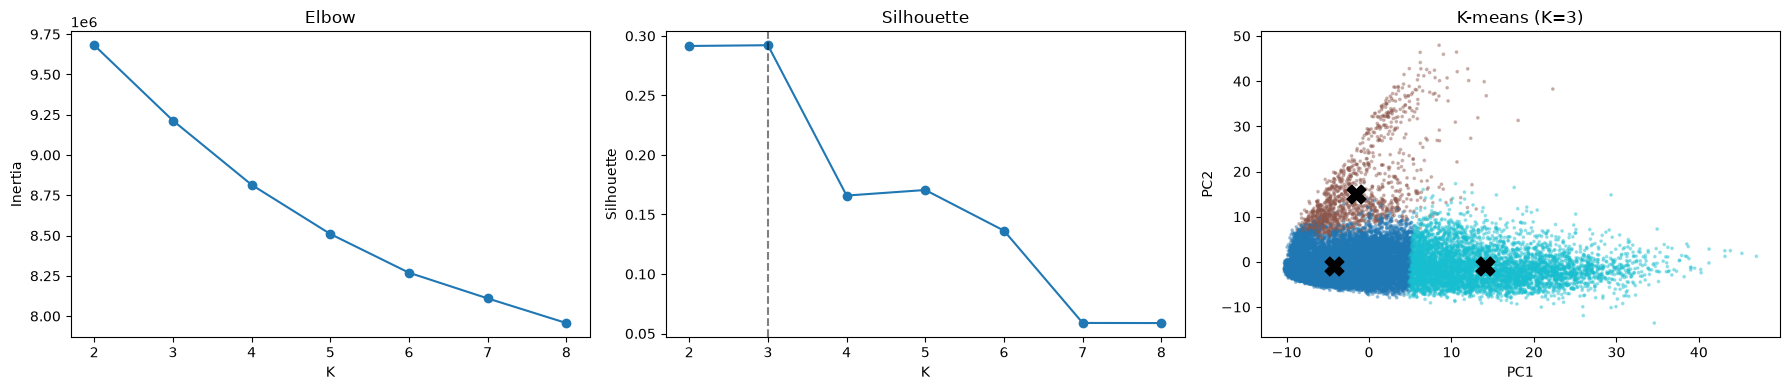

In [67]:
k_values = range(2, 9)
inertias = []
silhouettes = []
for k in k_values:
    candidate = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = candidate.fit_predict(X_pca)
    inertias.append(candidate.inertia_)
    silhouettes.append(silhouette_score(X_pca, labels, sample_size=5000, random_state=RANDOM_STATE))

cluster_diagnostics = pd.DataFrame({"K": list(k_values), "inertia": inertias, "silhouette": silhouettes})
display(cluster_diagnostics)
selected_k = int(cluster_diagnostics.loc[cluster_diagnostics["silhouette"].idxmax(), "K"])
print("Selected K:", selected_k)

kmeans = KMeans(n_clusters=selected_k, n_init=10, random_state=RANDOM_STATE)
cluster_labels = kmeans.fit_predict(X_pca)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(cluster_diagnostics["K"], cluster_diagnostics["inertia"], marker="o")
axes[0].set(xlabel="K", ylabel="Inertia", title="Elbow")
axes[1].plot(cluster_diagnostics["K"], cluster_diagnostics["silhouette"], marker="o")
axes[1].axvline(selected_k, color="black", linestyle="--", alpha=0.5)
axes[1].set(xlabel="K", ylabel="Silhouette", title="Silhouette")
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap="tab10", s=3, alpha=0.35)
axes[2].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="X", s=180, c="black")
axes[2].set(xlabel="PC1", ylabel="PC2", title=f"K-means (K={selected_k})")
plt.tight_layout()

3 сlustes as our labels in the dataset, but they distributed differently from the real values tho

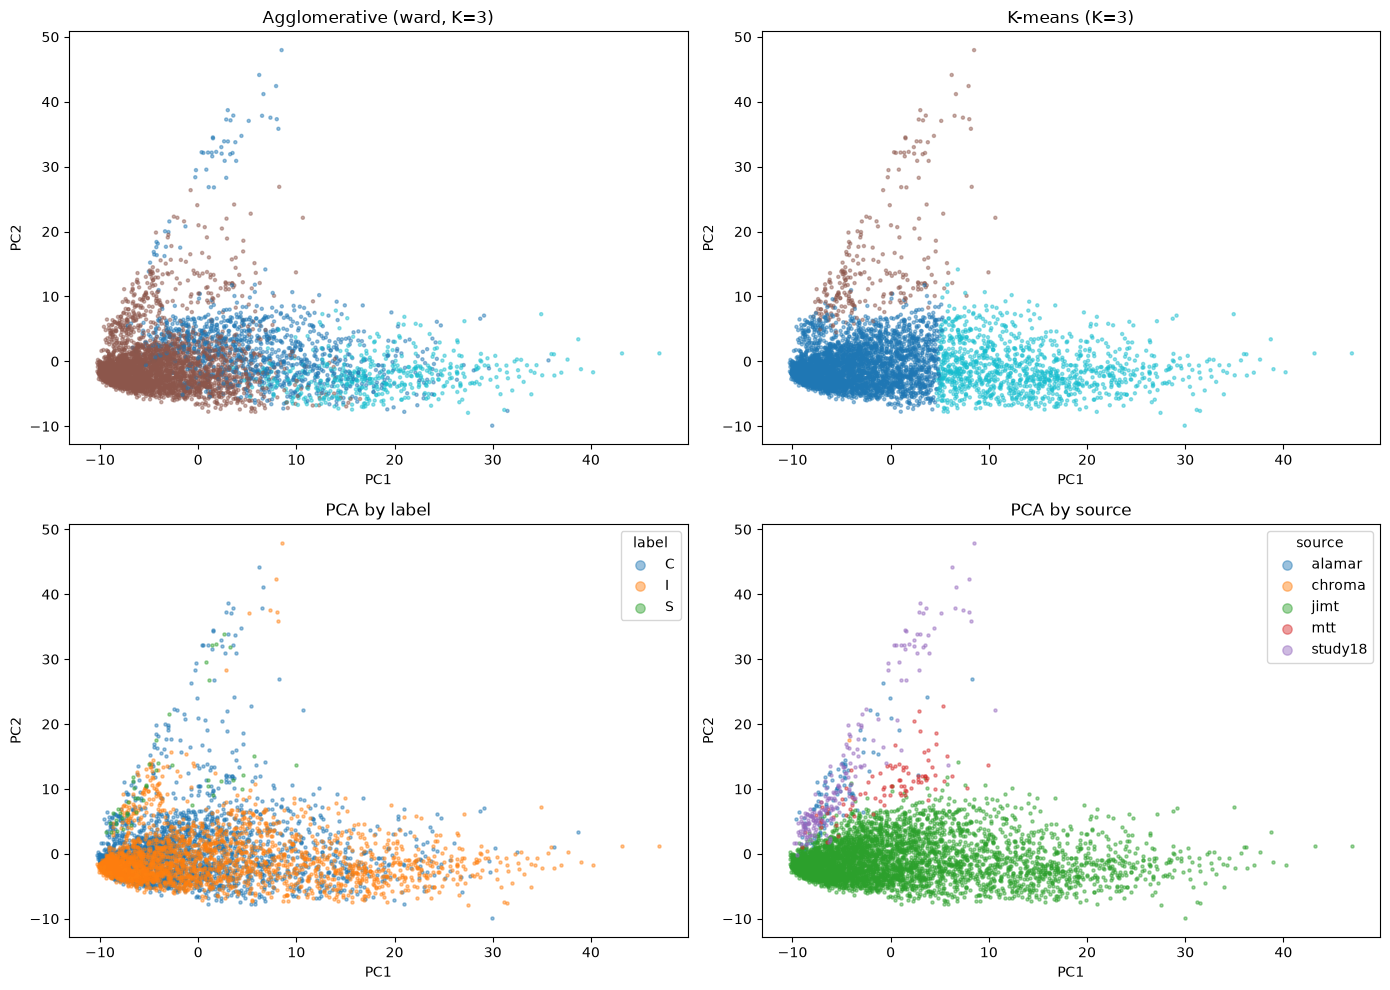

In [73]:
hierarchical_size = 5000
hierarchical_indices = np.random.default_rng(RANDOM_STATE).choice(len(X_pca), size=hierarchical_size, replace=False)
hierarchical_model = AgglomerativeClustering(n_clusters=selected_k, linkage="ward")
hierarchical_labels = hierarchical_model.fit_predict(X_pca[hierarchical_indices])

X_h = X_pca[hierarchical_indices]
label_h = data["label"].to_numpy()[hierarchical_indices]
source_h = data["source"].to_numpy()[hierarchical_indices]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].scatter(X_h[:, 0], X_h[:, 1], c=hierarchical_labels, cmap="tab10", s=5, alpha=0.45)
axes[0, 0].set(xlabel="PC1", ylabel="PC2", title=f"Agglomerative (ward, K={selected_k})")
axes[0, 1].scatter(X_h[:, 0], X_h[:, 1], c=cluster_labels[hierarchical_indices], cmap="tab10", s=5, alpha=0.45)
axes[0, 1].set(xlabel="PC1", ylabel="PC2", title=f"K-means (K={selected_k})")
for v in sorted(np.unique(label_h)):
    axes[1, 0].scatter(X_h[label_h == v, 0], X_h[label_h == v, 1], s=5, alpha=0.45, label=v)
axes[1, 0].set(xlabel="PC1", ylabel="PC2", title="PCA by label")
axes[1, 0].legend(title="label", markerscale=3)
for v in sorted(np.unique(source_h)):
    axes[1, 1].scatter(X_h[source_h == v, 0], X_h[source_h == v, 1], s=5, alpha=0.45, label=v)
axes[1, 1].set(xlabel="PC1", ylabel="PC2", title="PCA by source")
axes[1, 1].legend(title="source", markerscale=3)
plt.tight_layout()

In [76]:
kmeans_h = cluster_labels[hierarchical_indices]
label_h = data["label"].to_numpy()[hierarchical_indices]
source_h = data["source"].to_numpy()[hierarchical_indices]

print("K-means vs label   ARI:", adjusted_rand_score(label_h, kmeans_h), "NMI:", normalized_mutual_info_score(label_h, kmeans_h))
print("K-means vs source  ARI:", adjusted_rand_score(source_h, kmeans_h), "NMI:", normalized_mutual_info_score(source_h, kmeans_h))
print("Agglo vs label     ARI:", adjusted_rand_score(label_h, hierarchical_labels), "NMI:", normalized_mutual_info_score(label_h, hierarchical_labels))
print("Agglo vs source    ARI:", adjusted_rand_score(source_h, hierarchical_labels), "NMI:", normalized_mutual_info_score(source_h, hierarchical_labels))

display(pd.crosstab(label_h, kmeans_h, rownames=["label"], colnames=["kmeans"]))
display(pd.crosstab(label_h, hierarchical_labels, rownames=["label"], colnames=["agglomerative"]))
display(pd.crosstab(source_h, kmeans_h, rownames=["source"], colnames=["kmeans"]))
display(pd.crosstab(source_h, hierarchical_labels, rownames=["source"], colnames=["agglomerative"]))
display(pd.crosstab([source_h, label_h], kmeans_h, rownames=["source", "label"], colnames=["kmeans"]))
display(pd.crosstab([source_h, label_h], hierarchical_labels, rownames=["source", "label"], colnames=["agglomerative"]))

K-means vs label   ARI: 0.014256511895746086 NMI: 0.02642902305547278
K-means vs source  ARI: 0.2018671007406017 NMI: 0.29722640017009677
Agglo vs label     ARI: 0.008390519727440265 NMI: 0.027115055056737856
Agglo vs source    ARI: -0.05101109408356205 NMI: 0.03121618107890699


kmeans,0,1,2
label,,,
C,1830,133,447
I,1806,81,657
S,15,31,0


agglomerative,0,1,2
label,,,
C,632,1666,112
I,378,1813,353
S,9,37,0


kmeans,0,1,2
source,,,
alamar,36,62,0
chroma,0,1,0
jimt,3518,0,1104
mtt,10,78,0
study18,87,104,0


agglomerative,0,1,2
source,,,
alamar,0,98,0
chroma,1,0,0
jimt,967,3190,465
mtt,0,88,0
study18,51,140,0


kmeans            0   1    2
source  label               
alamar  C        19  28    0
        I        15  31    0
        S         2   3    0
chroma  S         0   1    0
jimt    C      1745   0  447
        I      1773   0  657
mtt     C         0  49    0
        I        10  19    0
        S         0  10    0
study18 C        66  56    0
        I         8  31    0
        S        13  17    0

agglomerative    0     1    2
source  label                
alamar  C        0    47    0
        I        0    46    0
        S        0     5    0
chroma  S        1     0    0
jimt    C      596  1484  112
        I      371  1706  353
mtt     C        0    49    0
        I        0    29    0
        S        0    10    0
study18 C       36    86    0
        I        7    32    0
        S        8    22    0

Based on the results k-meant captured some source representation  
K-means vs source  ARI: 0.2018671007406017 NMI: 0.29722640017009677, but others are arount 0  
crosstab source reveals that jimt is abscent from cluster 1 in k-means, other distributer between clusters
labels in both kinda enenly distributed between clusters, S is missing from cluster 2(but it doesnt really show biology)

## label decoding

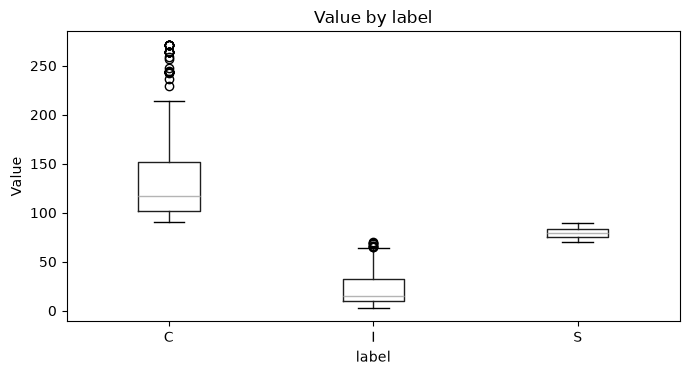

In [78]:
with_value = data[data["Value"].notna()]

fig, ax = plt.subplots(figsize=(7, 4))
with_value.boxplot(column="Value", by="label", ax=ax, grid=False)
ax.set(xlabel="label", ylabel="Value", title="Value by label")
plt.suptitle("")
plt.tight_layout()

im not sure, but if we'r deducting - C is probably from **control**, it's located around 100-150 in value count with some outliers(different images, different values in this class)
I - has smaller value, with mean arount 20, probably **inhibition** and S stays almost the same with small variation, smth like preservant that niether blocks, nor promotes the change of the value(i couldnt come up with the explanation for S in this case, mb **suppression**, but suppressed would've been lovering the value). I would've said that value is cell number in the image, but its continuous(even tho they kinda look like they were scaled from discrete, a lot of numbers are the same, which is unlikely for continuous data) 


another guess would be:

S - start, initial colony

C - control, not treated

I - induced, treated with drug

and continuous values are from some sort of normalization  
that my final guess